In [ ]:
import pandas as pd
import yfinance as yf
import numpy as np
from tqdm.notebook import tqdm

In [ ]:
ticker = 'AAPL'
data = yf.download(ticker, start='2025-01-01', end='2025-07-01', interval = '4h')
data.columns = data.columns.droplevel('Ticker')
# Tính giá điển hình (Typical Price) - hlc3
# Đây là "giá đại diện" cho mỗi cây nến, đúng như trong nghiên cứu
data['hlc3'] = (data['High'] + data['Low'] + data['Close']) / 3
# Tính giá trị giao dịch (Typical Price x Volume)
# Chuẩn bị sẵn tử số cho công thức VWAP
data['tp_vol'] = data['hlc3'] * data['Volume']
data

/tmp/ipython-input-85-1456010028.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start='2025-01-01', end='2025-07-01', interval = '4h')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume,hlc3,tp_vol
Datetime,,,,,,,
2025-01-02 14:30:00+00:00,242.686203,249.100006,242.309998,248.929993,31181025,244.698736,7.629957e+09
2025-01-02 18:30:00+00:00,243.820007,243.949997,241.820099,242.669998,16677886,243.196701,4.056007e+09
2025-01-03 14:30:00+00:00,243.009995,244.179993,241.889999,242.880203,21090325,243.026662,5.125511e+09
2025-01-03 18:30:00+00:00,243.300003,243.600006,242.570007,243.000000,10519351,243.156672,2.557850e+09
2025-01-06 14:30:00+00:00,245.029999,247.330002,243.839996,244.330002,22008569,245.399999,5.400903e+09
...,...,...,...,...,...,...,...
2025-06-26 17:30:00+00:00,200.940002,201.559998,199.975006,200.250000,14945060,200.825002,3.001342e+09
2025-06-27 13:30:00+00:00,202.080002,203.220001,200.854996,201.895004,26105106,202.051666,5.274580e+09
2025-06-27 17:30:00+00:00,201.100006,202.110001,200.220001,202.080002,16812475,201.143336,3.381717e+09


In [ ]:
def get_periods_per_year(freq: str) -> int:
    if freq.endswith('m'):  # phút
        minutes = int(freq[:-1])
        return int(365 * 24 * 60 / minutes)
    elif freq.endswith('h'):  # giờ
        hours = int(freq[:-1])
        return int(365 * 24 / hours)
    elif freq.endswith('d'):  # ngày
        return 365
    elif freq.endswith('w'):  # tuần
        return 52
    else:
        raise ValueError(f"Không hỗ trợ định dạng data_frequency: {freq}")

def calculate_sharpe_ratio(returns_series: pd.Series, data_frequency: str, annualized_risk_free_rate: float = 0.03) -> float:
    """
    Tính toán Sharpe Ratio hàng năm từ một chuỗi lợi nhuận theo kỳ.

    Args:
        returns_series (pd.Series): Chuỗi lợi nhuận của chiến lược theo từng kỳ.
        data_frequency (str): Tần suất của dữ liệu ('15m', '1H', '1D').
        annualized_risk_free_rate (float): Lãi suất phi rủi ro hàng năm.

    Returns:
        float: Giá trị Sharpe Ratio đã được quy đổi ra năm.
    """
    # Xử lý trường hợp không có giao dịch hoặc không có biến động
    if returns_series.std() == 0 or pd.isna(returns_series.std()):
        return 0.0

    # 1. Lấy số kỳ trong một năm
    periods_per_year = get_periods_per_year(data_frequency)

    # 2. Quy đổi lãi suất phi rủi ro ra theo từng kỳ
    rf_per_period = annualized_risk_free_rate / periods_per_year

    # 3. Tính toán Sharpe Ratio
    # Lợi nhuận trung bình mỗi kỳ trừ đi lãi suất phi rủi ro mỗi kỳ
    excess_return_mean = returns_series.mean() - rf_per_period

    # Sharpe Ratio hàng ngày = Lợi nhuận vượt trội trung bình / Độ lệch chuẩn lợi nhuận
    sharpe_ratio = excess_return_mean / returns_series.std()

    # 4. Quy đổi ra Sharpe Ratio hàng năm
    annualized_sharpe = sharpe_ratio * np.sqrt(periods_per_year)

    return annualized_sharpe

def backtest_vwap(df, a, b, fee_rate=0.00075):
    """
    Thực hiện backtest cho chiến lược giao cắt Rolling VWAP (MVWAP).
    Đây là chiến lược Long/Short, có tính đến phí giao dịch.

    Args:
        df (pd.DataFrame): DataFrame dữ liệu.
        a (int): Cửa sổ của MVWAP nhanh.
        b (int): Cửa sổ của MVWAP chậm.
        fee_rate (float): Tỷ lệ phí giao dịch (ví dụ: 0.075% = 0.00075).

    Returns:
        pd.Series: Chuỗi lợi nhuận của chiến lược sau khi đã trừ phí.
    """
    # 1. Tính toán hai đường MVWAP
    mvwap_fast = df['tp_vol'].rolling(window=a).sum() / (df['Volume'].rolling(window=a).sum() + 1e-9)
    mvwap_slow = df['tp_vol'].rolling(window=b).sum() / (df['Volume'].rolling(window=b).sum() + 1e-9)

    # 2. Tạo tín hiệu Long/Short (-1 = Short, 1 = Long)
    signal = np.sign(mvwap_fast - mvwap_slow)

    # 3. Tính toán lợi nhuận thị trường và dịch chuyển tín hiệu
    market_returns = df['Close'].pct_change()
    shifted_signal = signal.shift(1).fillna(0)

    # 4. Tính lợi nhuận chiến lược (chưa có phí)
    strategy_returns = market_returns * shifted_signal

    # 5. TÍNH TOÁN PHÍ GIAO DỊCH
    # Một giao dịch xảy ra khi tín hiệu thay đổi
    # .diff() sẽ khác 0 khi signal thay đổi (ví dụ: từ 1 sang -1, .diff() = -2)
    trades = shifted_signal.diff().ne(0)
    trade_count = trades.sum()
    trade_times = df.index[trades].tolist()
    # print (trade_count)
    # print (trade_times)


    # Trừ phí vào lợi nhuận tại những cây nến có giao dịch
    strategy_returns[trades] -= fee_rate

    return strategy_returns.fillna(0)
def sweep_vwap(df, a_range, b_range):
    """
    Quét qua các tham số khác nhau của chiến lược MVWAP crossover.

    Args:
        df (pd.DataFrame): DataFrame dữ liệu.
        a_range (range): Dải tham số cho MVWAP nhanh.
        b_range (range): Dải tham số cho MVWAP chậm.

    Returns:
        dict: Dictionary với key là (a, b) và value là tuple (cumm_returns, sharpe).
    """
    results = {}  # Store both cumulative returns and Sharpe Ratio

    for a in tqdm(a_range, desc="Quét MVWAP"):
        for b in b_range:
            if a < b:  # Ensure fast MVWAP period is shorter than slow MVWAP
                bt_returns = backtest_vwap(df, a, b)
                cumm_returns = (1 + bt_returns).cumprod()
                sharpe = calculate_sharpe_ratio(bt_returns, '4h')
                results[(a, b)] = (cumm_returns, sharpe)  # Store both

    return results

In [ ]:

# Parameter ranges
a_range = range(2, 100, 2)  # Fast MVWAP periods
b_range = range(2, 610, 2)  # Slow MVWAP periods

# Run sweep test
results = sweep_vwap(data, a_range, b_range)

# Sort results by Sharpe Ratio (descending)
sorted_results = sorted(results.items(), key=lambda item: item[1][1], reverse=True)

# Print top 5 parameter pairs
print("\n--- 5 cặp tham số MVWAP tốt nhất (dựa trên Sharpe Ratio) ---")
for params, (cumm_returns, sharpe) in sorted_results[:5]:
    print(f"MVWAP Nhanh: {params[0]}, MVWAP Chậm: {params[1]} -> Sharpe Ratio (năm): {sharpe:.2f}, Cumulative Returns (final): {cumm_returns.iloc[-1]:.2f}")

Quét MVWAP:   0%|          | 0/49 [00:00<?, ?it/s]


--- 5 cặp tham số MVWAP tốt nhất (dựa trên Sharpe Ratio) ---
MVWAP Nhanh: 72, MVWAP Chậm: 88 -> Sharpe Ratio (năm): 3.32, Cumulative Returns (final): 1.26
MVWAP Nhanh: 8, MVWAP Chậm: 12 -> Sharpe Ratio (năm): 3.17, Cumulative Returns (final): 1.28
MVWAP Nhanh: 72, MVWAP Chậm: 90 -> Sharpe Ratio (năm): 2.97, Cumulative Returns (final): 1.22
MVWAP Nhanh: 72, MVWAP Chậm: 92 -> Sharpe Ratio (năm): 2.84, Cumulative Returns (final): 1.21
MVWAP Nhanh: 74, MVWAP Chậm: 88 -> Sharpe Ratio (năm): 2.82, Cumulative Returns (final): 1.22


/tmp/ipython-input-6-767018545.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price              Close          High           Low          Open  \
Date                                                                 
2023-07-24  29176.916016  30093.394531  28934.294922  30081.662109   
2023-07-25  29227.390625  29353.160156  29062.433594  29178.970703   
2023-07-26  29354.972656  29675.552734  29113.912109  29225.759766   
2023-07-27  29210.689453  29560.966797  29099.351562  29353.798828   
2023-07-28  29319.246094  29521.513672  29125.845703  29212.164062   

Price            Volume  
Date                     
2023-07-24  15395817395  
2023-07-25  10266772793  
2023-07-26  13497554655  
2023-07-27  10770779217  
2023-07-28  11218474952  
Backtest Results for BTC-USD
Total Return: 284.61%
Annualized Return: 59.20%
Sharpe Ratio: 1.36


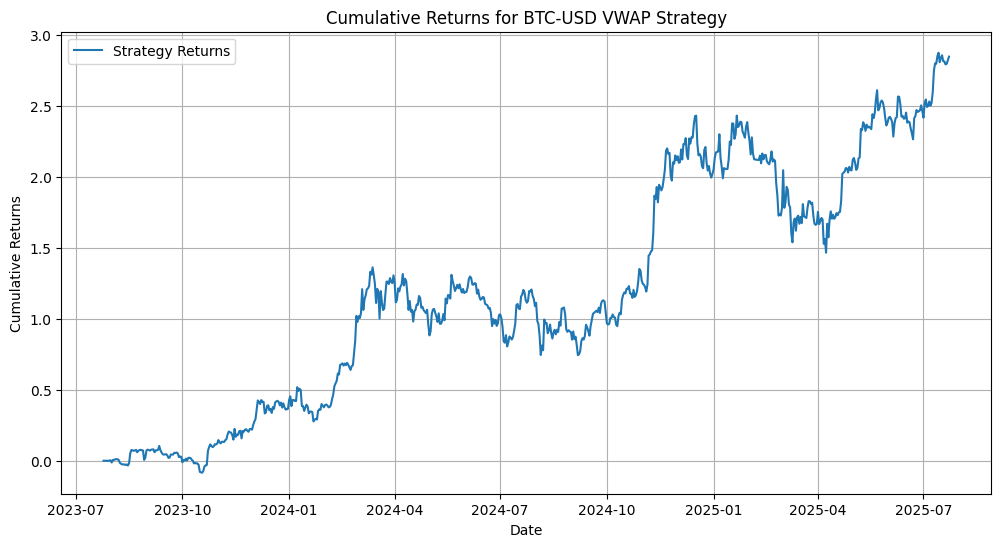

In [6]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Download stock data
def get_data(ticker, start_date, end_date):
   df = yf.download(ticker, start=start_date, end=end_date)
   df.columns = df.columns.droplevel('Ticker')
   print (df.head())
   return df

# Calculate VWAP
def calculate_vwap(df):
    df['Typical_Price'] = (df['High'] + df['Low'] + df['Close']) / 3
    df['TP_Volume'] = df['Typical_Price'] * df['Volume']
    df['Cumulative_TP_Volume'] = df['TP_Volume'].cumsum()
    df['Cumulative_Volume'] = df['Volume'].cumsum()
    df['VWAP'] = df['Cumulative_TP_Volume'] / df['Cumulative_Volume']
    return df

# Calculate 5-day Moving VWAP
def calculate_mvwap(df, window=5):
    df['MVWAP'] = df['VWAP'].rolling(window=window).mean()
    return df

# Generate trading signals
def generate_signals(df):
    df['Signal'] = 0
    df['Signal'] = np.where(df['VWAP'] > df['MVWAP'], 1, df['Signal'])
    df['Signal'] = np.where(df['VWAP'] < df['MVWAP'], -1, df['Signal'])
    df['Position'] = df['Signal'].shift(1)  # Shift to avoid look-ahead bias
    return df

# Calculate returns
def calculate_returns(df):
    df['Returns'] = df['Close'].pct_change()
    df['Strategy_Returns'] = df['Position'] * df['Returns']
    df['Cumulative_Returns'] = (1 + df['Strategy_Returns']).cumprod() - 1
    return df

# Backtest function
def backtest(ticker, start_date, end_date):
    # Get data
    df = get_data(ticker, start_date, end_date)

    # Calculate indicators
    df = calculate_vwap(df)
    df = calculate_mvwap(df)

    # Generate signals
    df = generate_signals(df)

    # Calculate returns
    df = calculate_returns(df)

    # Performance metrics
    total_return = df['Cumulative_Returns'].iloc[-1]
    annual_return = ((1 + total_return) ** (252 / len(df))) - 1
    sharpe_ratio = df['Strategy_Returns'].mean() / df['Strategy_Returns'].std() * np.sqrt(252)

    return df, total_return, annual_return, sharpe_ratio

# Run backtest
if __name__ == "__main__":
    ticker = "BTC-USD"  # Example ticker
    end_date = datetime.now()
    start_date = end_date - timedelta(days=365*2)  # 2 years of data

    df, total_return, annual_return, sharpe_ratio = backtest(ticker, start_date, end_date)

    print(f"Backtest Results for {ticker}")
    print(f"Total Return: {total_return:.2%}")
    print(f"Annualized Return: {annual_return:.2%}")
    print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

    # Optional: Plot results
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12,6))
    plt.plot(df.index, df['Cumulative_Returns'], label='Strategy Returns')
    plt.title(f'Cumulative Returns for {ticker} VWAP Strategy')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Returns')
    plt.legend()
    plt.grid()
    plt.show()